# **Chapter 3: The synthetic booking history**

## **Loca-T demand forecasting: Chapter 3, synthetic booking history**

## Why synthetic
No public dataset records what small Kenyan hosts actually booked. To build and test
the price advisor end to end we generate a believable daily occupancy history for five
destinations from 1 Jan 2024 up to today.

## What this proves, and what it does not
- It **does** show that the pipeline works: data in, forecast out, price advice out.
- It does **not** show that the model predicts real demand. A model fitted to data we
  generated mostly recovers the rules we wrote in.
- The real-data claim stays in Chapter 1: the international seasonal index forecast
  Jan-Jun 2026 arrivals to within about 4%.

## Structure
occupancy = base level of the destination
  x [ intl_share x (real international index, smoothed)
    + (1 - intl_share) x (domestic calendar effects) ]
  x destination adjustment for the month (ASSUMED)
  x random noise

**Real inputs:** international index, school calendar, public holidays, long weekends.
**Assumed inputs:** everything in the tables below. They come from general knowledge of
Kenyan travel (weekend trips to Naivasha, long rains from March to May, the Mara
migration from July to October, the coast's peak at Christmas), not from data we
verified. Read them, change what you disagree with, then we generate.

## This cell's job
Define the assumptions as tables and print them so they can be reviewed.

In [1]:
import pandas as pd

DESTINATIONS = ["Maasai Mara", "Naivasha", "Diani", "Lamu", "Amboseli"]

# One row per destination. ALL VALUES ARE ASSUMPTIONS.
params = pd.DataFrame({
    #                   Mara   Naivasha  Diani  Lamu  Amboseli
    "base_occupancy":   [0.50,  0.40,     0.50,  0.45, 0.45],  # typical share of rooms filled
    "intl_share":       [0.60,  0.10,     0.45,  0.45, 0.65],  # share of guests from abroad
    "weekend_boost":    [1.10,  1.60,     1.25,  1.20, 1.10],  # Fri/Sat night, domestic guests
    "school_boost":     [1.25,  1.30,     1.50,  1.35, 1.25],  # school holidays, domestic guests
    "longwknd_boost":   [1.15,  1.45,     1.35,  1.25, 1.20],  # long weekends, domestic guests
}, index=DESTINATIONS).T

# Destination's own season, on top of the national pattern (1.0 = no adjustment)
month_adjust = pd.DataFrame({
    "Maasai Mara": [1.00, 1.00, 0.95, 0.85, 0.85, 1.00, 1.15, 1.20, 1.20, 1.15, 0.95, 1.00],
    "Naivasha":    [1.00, 1.00, 1.00, 0.95, 0.95, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.05],
    "Diani":       [1.15, 1.10, 1.00, 0.85, 0.75, 0.80, 1.05, 1.05, 1.00, 1.00, 0.95, 1.20],
    "Lamu":        [1.15, 1.10, 1.00, 0.85, 0.75, 0.80, 1.05, 1.05, 1.00, 1.00, 0.95, 1.20],
    "Amboseli":    [1.10, 1.10, 1.00, 0.85, 0.85, 1.00, 1.15, 1.15, 1.10, 1.05, 0.90, 1.05],
}, index=[pd.Timestamp(2000, m, 1).strftime("%b") for m in range(1, 13)]).T

# Effects that apply to every destination
globals_ = {
    "easter_extra":   1.10,  # extra lift on Easter days, on top of the long weekend
    "payday_boost":   1.05,  # day 25 to day 3 of the month (no data to measure this)
    "noise_sd":       0.12,  # day-to-day randomness (log scale)
    "occupancy_cap":  0.98,  # a destination can never be more than full
}

print("DESTINATION ASSUMPTIONS")
print(params.to_string())
print("\nMONTHLY ADJUSTMENT (destination's own season)")
print(month_adjust.to_string())
print("\nGLOBAL ASSUMPTIONS")
for k, v in globals_.items():
    print(f"  {k:14s} {v}")

DESTINATION ASSUMPTIONS
                Maasai Mara  Naivasha  Diani  Lamu  Amboseli
base_occupancy         0.50      0.40   0.50  0.45      0.45
intl_share             0.60      0.10   0.45  0.45      0.65
weekend_boost          1.10      1.60   1.25  1.20      1.10
school_boost           1.25      1.30   1.50  1.35      1.25
longwknd_boost         1.15      1.45   1.35  1.25      1.20

MONTHLY ADJUSTMENT (destination's own season)
              Jan  Feb   Mar   Apr   May  Jun   Jul   Aug  Sep   Oct   Nov   Dec
Maasai Mara  1.00  1.0  0.95  0.85  0.85  1.0  1.15  1.20  1.2  1.15  0.95  1.00
Naivasha     1.00  1.0  1.00  0.95  0.95  1.0  1.00  1.00  1.0  1.00  1.00  1.05
Diani        1.15  1.1  1.00  0.85  0.75  0.8  1.05  1.05  1.0  1.00  0.95  1.20
Lamu         1.15  1.1  1.00  0.85  0.75  0.8  1.05  1.05  1.0  1.00  0.95  1.20
Amboseli     1.10  1.1  1.00  0.85  0.85  1.0  1.15  1.15  1.1  1.05  0.90  1.05

GLOBAL ASSUMPTIONS
  easter_extra   1.1
  payday_boost   1.05
  noise_sd    

## **Generating the history**

Using the assumptions printed above (unchanged), we generate daily occupancy for each
destination from 1 Jan 2024 to 5 Nov 2026.

**Design choices**
1. **Smoothed international index.** The monthly index is interpolated between
   mid-month points so there is no artificial jump at month boundaries.
2. **Normalised domestic effects.** Weekend, school, long-weekend, Easter and payday
   boosts are multiplied and then divided by their own average, so `base_occupancy`
   keeps its meaning ("typical share of rooms filled").
3. **Two series.** `latent_demand` is demand without a capacity limit; `occupancy` is
   that, capped at 98%. A host only observes occupancy, so peak demand is hidden
   (censored). We keep both so we can measure how much demand the cap hides.
4. **Extra assumptions added in this step:** market growth 5% a year, day-to-day noise
   that is correlated between neighbouring days (AR(1), 0.5), and a fixed random seed.

**Checks after generation**
- Mean occupancy per destination should be near its base (a little above, because of
  growth).
- No destination should sit at the cap on most days.
- Monthly patterns should echo each destination's own season.
- Weekend, school-break and long-weekend days should show uplift.

Everything is saved with its assumptions in `synthetic_assumptions.json`, so the data
can always be traced back to the rules that produced it.

rows: 5200 | destinations: 5 | dates: 2024-01-01 to 2026-11-05
missing values: 0

Per destination:
             base  mean_occupancy  min_occ  max_occ  share_days_capped  demand_hidden_by_cap
destination                                                                                 
Maasai Mara  0.50           0.552    0.263    0.980              0.004                 0.000
Naivasha     0.40           0.420    0.214    0.980              0.004                 0.001
Diani        0.50           0.532    0.239    0.980              0.005                 0.001
Lamu         0.45           0.478    0.228    0.876              0.000                 0.000
Amboseli     0.45           0.499    0.238    0.945              0.000                 0.000

Mean occupancy by month (2024-2025):
              Jan   Feb   Mar   Apr   May   Jun   Jul   Aug   Sep   Oct   Nov   Dec
destination                                                                        
Maasai Mara  0.51  0.48  0.44  0.40  0.39  0

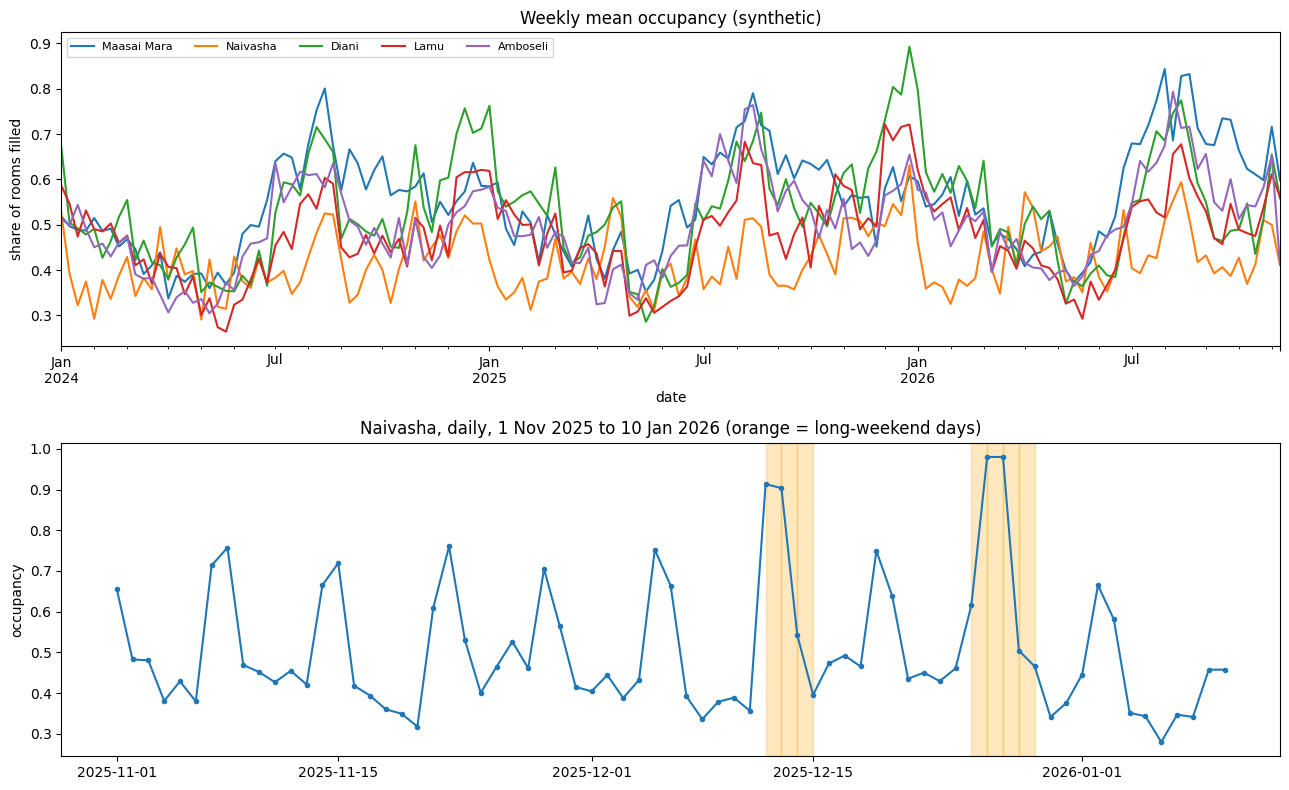

In [4]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

out_dir = Path("../data/processed")
cal = pd.read_csv(out_dir / "calendar_daily.csv", parse_dates=["date"])
seasonal = pd.read_csv(out_dir / "seasonal_index.csv")
idx_map = dict(zip(seasonal["month_number"], seasonal["seasonal_index"]))

globals_.update({"annual_growth": 0.05, "noise_ar": 0.5, "seed": 42})
HISTORY_END = pd.Timestamp("2026-11-05")
month_labels = [pd.Timestamp(2000, m, 1).strftime("%b") for m in range(1, 13)]

# 1) Smooth the international index: linear between mid-month anchors
anchors = pd.date_range("2023-12-01", "2027-05-01", freq="MS") + pd.Timedelta(days=14)
anchor_vals = [idx_map[a.month] for a in anchors]
cal["intl_smooth"] = np.interp(
    cal["date"].map(pd.Timestamp.toordinal),
    [a.toordinal() for a in anchors],
    anchor_vals,
)

# 2) Market growth
years = (cal["date"] - pd.Timestamp("2024-01-01")).dt.days / 365.25
growth = ((1 + globals_["annual_growth"]) ** years).to_numpy()

rng = np.random.default_rng(globals_["seed"])
phi, sd = globals_["noise_ar"], globals_["noise_sd"]
in_history = (cal["date"] <= HISTORY_END).to_numpy()

frames = []
for dest in DESTINATIONS:
    p = params[dest]

    # Domestic effects, normalised so their average over the history is 1
    domestic = (
        np.where(cal["fri_sat_night"] == 1, p["weekend_boost"], 1.0)
        * np.where(cal["school_out"] == 1, p["school_boost"], 1.0)
        * np.where(cal["is_long_weekend"] == 1, p["longwknd_boost"], 1.0)
        * np.where(cal["easter_period"] == 1, globals_["easter_extra"], 1.0)
        * np.where(cal["payday_window"] == 1, globals_["payday_boost"], 1.0)
    )
    domestic = domestic / domestic[in_history].mean()

    mixture = p["intl_share"] * cal["intl_smooth"].to_numpy() + (1 - p["intl_share"]) * domestic
    own_season = cal["month"].map(
        lambda m: month_adjust.loc[dest, month_labels[m - 1]]
    ).to_numpy()

    # AR(1) noise on the log scale: neighbouring days share some luck
    z = rng.standard_normal(len(cal))
    e = np.zeros(len(cal))
    for t in range(1, len(cal)):
        e[t] = phi * e[t - 1] + np.sqrt(1 - phi**2) * z[t]
    noise = np.exp(sd * e - 0.5 * sd**2)

    latent = p["base_occupancy"] * growth * mixture * own_season * noise
    frames.append(pd.DataFrame({
        "date": cal["date"],
        "destination": dest,
        "latent_demand": latent,
        "occupancy": np.minimum(latent, globals_["occupancy_cap"]),
    }))

syn = pd.concat(frames, ignore_index=True)
syn = syn[syn["date"] <= HISTORY_END].reset_index(drop=True)
syn["source"] = "synthetic"

# ---- checks ----
cap = globals_["occupancy_cap"]
print("rows:", len(syn), "| destinations:", syn["destination"].nunique(),
      "| dates:", syn["date"].min().date(), "to", syn["date"].max().date())
print("missing values:", int(syn.isna().sum().sum()))

summary = syn.groupby("destination").agg(
    mean_occupancy=("occupancy", "mean"),
    min_occ=("occupancy", "min"),
    max_occ=("occupancy", "max"),
    share_days_capped=("latent_demand", lambda s: (s > cap).mean()),
    demand_hidden_by_cap=("latent_demand", lambda s: 0.0),  # filled below
).loc[DESTINATIONS]
sums = syn.groupby("destination")[["occupancy", "latent_demand"]].sum()
lost = 1 - sums["occupancy"] / sums["latent_demand"]
summary["demand_hidden_by_cap"] = lost
summary.insert(0, "base", params.loc["base_occupancy"])
print("\nPer destination:")
print(summary.round(3).to_string())

tmp = syn.assign(year=syn["date"].dt.year, month=syn["date"].dt.month)
by_month = (
    tmp[tmp["year"].isin([2024, 2025])]
    .pivot_table(index="destination", columns="month", values="occupancy", aggfunc="mean")
    .loc[DESTINATIONS]
)
by_month.columns = month_labels
print("\nMean occupancy by month (2024-2025):")
print(by_month.round(2).to_string())

flags = cal[["date", "fri_sat_night", "school_out", "is_long_weekend"]]
x = syn.merge(flags, on="date")
def ratio(col):
    g = x.groupby(["destination", col])["occupancy"].mean().unstack()
    return g[1] / g[0]
effects = pd.DataFrame({
    "fri_sat_vs_other": ratio("fri_sat_night"),
    "school_out_vs_in": ratio("school_out"),
    "long_wknd_vs_other": ratio("is_long_weekend"),
}).loc[DESTINATIONS]
print("\nObserved uplift (ratio of mean occupancy; overlaps between effects blur these):")
print(effects.round(2).to_string())

# ---- save ----
syn.to_csv(out_dir / "synthetic_occupancy.csv", index=False)
assumptions = {
    "note": "ALL VALUES ARE ASSUMPTIONS used to generate SYNTHETIC data. Not real bookings.",
    "params": params.to_dict(),
    "month_adjust": month_adjust.to_dict(orient="index"),
    "globals": globals_,
}
(out_dir / "synthetic_assumptions.json").write_text(json.dumps(assumptions, indent=2, default=float))
print("\nsaved: synthetic_occupancy.csv and synthetic_assumptions.json")

# ---- pictures ----
weekly = syn.set_index("date").groupby("destination")["occupancy"].resample("W").mean()
fig, axes = plt.subplots(2, 1, figsize=(13, 8))
for dest in DESTINATIONS:
    weekly.loc[dest].plot(ax=axes[0], label=dest)
axes[0].set_title("Weekly mean occupancy (synthetic)")
axes[0].set_ylabel("share of rooms filled")
axes[0].legend(ncol=5, fontsize=8)

zoom = syn[(syn["destination"] == "Naivasha") & (syn["date"] >= "2025-11-01") & (syn["date"] <= "2026-01-10")]
axes[1].plot(zoom["date"], zoom["occupancy"], marker=".")
lw = cal[(cal["date"] >= "2025-11-01") & (cal["date"] <= "2026-01-10") & (cal["is_long_weekend"] == 1)]
for d in lw["date"]:
    axes[1].axvspan(d, d + pd.Timedelta(days=1), color="orange", alpha=0.25)
axes[1].set_title("Naivasha, daily, 1 Nov 2025 to 10 Jan 2026 (orange = long-weekend days)")
axes[1].set_ylabel("occupancy")
plt.tight_layout()
plt.show()

## **3.3 Review of results: the generated history (step 3.2)**

### **3.3.1 Verdict**
The generator works as designed. It produced 5,200 rows (5 destinations x 1,040 days,
1 Jan 2024 to 5 Nov 2026) with no missing values, saved together with its assumptions.
Seasons, weekend effects and school effects all behave as intended. One number, the
long-weekend uplift below 1.0 for Maasai Mara and Amboseli, needs an explanation and a
test. That test is step 3.4.

### **3.3.2 What the numbers show**

#### **3.3.2.1 Mean occupancy against the base**

| Destination | Base | Mean | Difference |
|---|---|---|---|
| Maasai Mara | 0.50 | 0.552 | +10% |
| Naivasha | 0.40 | 0.420 | +5% |
| Diani | 0.50 | 0.532 | +6% |
| Lamu | 0.45 | 0.478 | +6% |
| Amboseli | 0.45 | 0.499 | +11% |

All five sit slightly above their base, as expected: 5% yearly market growth lifts the
average by about 7% over the period. Mara and Amboseli rise a few points more, probably
because they have large international shares and the window contains three Julys to
Octobers but only two Novembers and Decembers.

#### **3.3.2.2 Capacity**
Days at the 98% cap: 0.4% (Mara), 0.4% (Naivasha), 0.5% (Diani), none for Lamu and
Amboseli. The demand hidden by the cap is 0.1% or less. In this data, censoring is real
but small, which is less than I suggested before the run. We keep both columns anyway.
The chart shows the clearest case: Naivasha is sold out on the Christmas 2025 long
weekend (two flat-top days at 0.98).

#### **3.3.2.3 Each destination's own season**

| Destination | Assumed season | Observed peak | Observed low | Verdict |
|---|---|---|---|---|
| Maasai Mara | Jul to Oct high | Aug 0.72 | May 0.39 | matches |
| Naivasha | follows school holidays | Dec 0.51, Nov 0.49, Aug 0.48 | May 0.35 | matches |
| Diani | Dec high, May to Jun low | Dec 0.75 | May 0.34 | matches |
| Lamu | Dec high, May to Jun low | Dec 0.66 | May 0.30 | matches |
| Amboseli | Jul to Aug high, Apr to May low | Aug 0.64 | Apr 0.35 | matches |

Naivasha is the instructive case: it is nearly flat across the year and follows the
school calendar (high in November, December, August and April, low in May and July),
not the international season. That is the contrast we wanted between a domestic and an
international destination.

#### **3.3.2.4 Weekend, school and long-weekend uplift**

| Destination | Weekend assumed / observed | School assumed / observed | Long weekend assumed / observed |
|---|---|---|---|
| Maasai Mara | 1.10 / 1.04 | 1.25 / 1.07 | 1.15 / 0.97 |
| Naivasha | 1.60 / 1.58 | 1.30 / 1.32 | 1.45 / 1.62 |
| Diani | 1.25 / 1.14 | 1.50 / 1.34 | 1.35 / 1.14 |
| Lamu | 1.20 / 1.12 | 1.35 / 1.23 | 1.25 / 1.14 |
| Amboseli | 1.10 / 1.04 | 1.25 / 1.08 | 1.20 / 0.95 |

The observed weekend ratios match a simple mixing rule: only the domestic share of
guests responds, so the uplift is about intl_share + (1 - intl_share) x boost. For
Maasai Mara that is 0.6 + 0.4 x 1.10 = 1.04, exactly the observed value; for Diani it
is 0.45 + 0.55 x 1.25 = 1.14, also exact. This is good evidence that the generator
does what the assumptions table says.

Two long-weekend numbers need care. Naivasha's 1.62 is higher than the rule predicts
(about 1.41) because long weekends contain Fridays and Saturdays, so the weekend and
long-weekend effects overlap. Mara (0.97) and Amboseli (0.95) fall below 1.0, which
looks wrong. My hypothesis: long weekends cluster in the rainy low season (9 long-weekend
days each in March, April, May and October), when those two destinations are quiet
for other reasons, so the raw ratio mixes season with day type. It is a hypothesis, not
a conclusion, and step 3.4 tests it.

#### **3.3.2.5 Charts**
- **Weekly view:** Mara and Amboseli rise from July to October each year; Diani and
  Lamu peak at year end; Naivasha is lowest and spikiest.
- **Naivasha daily view:** a clear weekend sawtooth (roughly 0.70 to 0.76 against 0.35 to
  0.48 on weekdays), spikes of about 0.9 on the 12 to 14 December 2025 long weekend, and
  the capped Christmas days.
- **No cliffs at month boundaries.** The smoothing of the international index works.

### **3.3.3 Limits**
Everything above shows that the generator reproduces the rules we wrote into it. It
tests the machinery, not the real world. The real-data evidence remains Chapter 1.

### **3.3.4 Housekeeping**
The pandas DeprecationWarning is harmless. It comes from the `.apply` used to compute
the share of demand hidden by the cap, and can be silenced with a small edit (see the
note after this cell).

## **3.4 Next step: a within-month check of the day-type effects**

### **3.4.1 Why**
Raw ratios mix two things: the effect of the day type (weekend, school break, long
weekend) and the season in which those days happen. The long-weekend ratio below 1.0
for Maasai Mara and Amboseli may be only the second one.

### **3.4.2 Method**
For each destination, year and month, divide each day's occupancy by that month's
average. This removes the season. Then compare days with and without each flag inside
the same month, using only months that contain both kinds of day.

For long weekends we compare only Friday and Saturday nights (long-weekend ones against
ordinary ones). That removes the overlap with the weekend effect, so we measure the
long-weekend effect alone.

### **3.4.3 What we expect**
The mixing rule, intl_share + (1 - intl_share) x boost, gives approximate targets,
within a few hundredths. The long-weekend targets are about 1.06 (Mara), 1.41 (Naivasha),
1.19 (Diani), 1.14 (Lamu) and 1.07 (Amboseli).

### **3.4.4 Decision rule**
- If every within-month long-weekend uplift is above 1.0 and close to its target, the
  seasonal-mixing explanation holds and the generator is correct.
- If any stays below 1.0, there is a bug in the long-weekend logic, and we will find it
  before building anything on top of this data.

In [5]:
df = syn.merge(cal[["date", "fri_sat_night", "school_out", "is_long_weekend"]], on="date")
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month


def within_month_uplift(data, flag):
    """Ratio of occupancy (relative to its own month) on flagged vs unflagged days,
    using only months that contain both kinds of day."""
    g = data.groupby(["destination", "year", "month"])
    d = data.assign(
        rel=data["occupancy"] / g["occupancy"].transform("mean"),
        has_both=g[flag].transform("nunique") == 2,
    )
    d = d[d["has_both"]]
    m = d.groupby(["destination", flag])["rel"].mean().unstack()
    return m[1] / m[0]


fri_sat_only = df[df["fri_sat_night"] == 1]
observed = pd.DataFrame({
    "fri_sat_vs_other": within_month_uplift(df, "fri_sat_night"),
    "school_out_vs_in": within_month_uplift(df, "school_out"),
    "long_wknd_vs_normal_fri_sat": within_month_uplift(fri_sat_only, "is_long_weekend"),
}).loc[DESTINATIONS]

s = params.loc["intl_share"]
expected = pd.DataFrame({
    "fri_sat_vs_other": s + (1 - s) * params.loc["weekend_boost"],
    "school_out_vs_in": s + (1 - s) * params.loc["school_boost"],
    "long_wknd_vs_normal_fri_sat": s + (1 - s) * params.loc["longwknd_boost"],
}).loc[DESTINATIONS]

print("Observed within-month uplift:")
print(observed.round(2).to_string())
print("\nTarget from the mixing rule (approximate):")
print(expected.round(2).to_string())
print("\nDifference (observed - target):")
print((observed - expected).round(2).to_string())

# How much data stands behind each number (Naivasha as an example; flags are shared)
nv = df[df["destination"] == "Naivasha"]
def months_with_both(data, flag):
    return int((data.groupby(["year", "month"])[flag].nunique() == 2).sum())
print("\nMonths that contain both kinds of day:",
      {"fri_sat": months_with_both(nv, "fri_sat_night"),
       "school": months_with_both(nv, "school_out"),
       "long_weekend (Fri/Sat nights)": months_with_both(nv[nv["fri_sat_night"] == 1], "is_long_weekend")})

Observed within-month uplift:
             fri_sat_vs_other  school_out_vs_in  long_wknd_vs_normal_fri_sat
destination                                                                 
Maasai Mara              1.05              1.05                         1.06
Naivasha                 1.57              1.21                         1.46
Diani                    1.14              1.20                         1.10
Lamu                     1.12              1.12                         1.19
Amboseli                 1.04              1.08                         1.02

Target from the mixing rule (approximate):
             fri_sat_vs_other  school_out_vs_in  long_wknd_vs_normal_fri_sat
Maasai Mara              1.04              1.10                         1.06
Naivasha                 1.54              1.27                         1.40
Diani                    1.14              1.28                         1.19
Lamu                     1.11              1.19                         1.14
Am

## **3.6 Next step: move the generator into the project and separate noise from bias**

### **3.6.1 Why**
There are two reasons, one about engineering and one about measurement.

1. **Engineering:** the generator belongs in `src/locat/forecasting/synthetic.py`, so
   notebooks and the app use the same code, and changing an assumption means rerunning
   one function.
2. **Measurement:** one random draw (seed 42) cannot tell noise from a systematic
   difference. Running the same generator on many seeds can.

### **3.6.2 Method**
1. Write the generator as a function in `synthetic.py`.
2. **Regression test:** the function, given the same inputs and seed 42, must reproduce
   exactly the history we generated in 3.2.
3. Run the function with 20 other seeds. For each run compute the same three
   within-month uplifts as in 3.4.
4. Compare:
   - the average over seeds against the target gives the **bias** of the target formula;
   - the spread (standard deviation) across seeds gives the **noise** in one run;
   - our seed-42 run, in standard deviations from the average, shows how unusual it is.

### **3.6.3 Decision rule**
- If the average is within 0.03 of the target, the target formula is adequate and our
  gaps are sampling noise (when the seed-42 run is within 2 standard deviations).
- If the average differs from the target by more than 0.05 with the same sign, the
  difference is systematic. We then either document it ("the effective school uplift is
  5 to 8 points below the assumed boost") or change the assumption, but we do not tune
  parameters just to hit the target.
- If the seed-42 run is more than 2 standard deviations from the average for some
  cell, we keep the data, mark that cell as less reliable, and do not re-roll seeds.

In [6]:
import importlib
import sys

sys.path.insert(0, str(Path("../src").resolve()))
import locat.forecasting.synthetic as synth

importlib.reload(synth)

# 1) Regression test: the function must reproduce the history from step 3.2
rebuilt = synth.generate_history(cal, params, month_adjust, globals_, idx_map, HISTORY_END)
pd.testing.assert_frame_equal(rebuilt, syn.reset_index(drop=True)[rebuilt.columns])
print("regression test passed: the function reproduces the step 3.2 history\n")

# 2) Same three uplifts as step 3.4, repeated over 20 other seeds
flag_cols = cal[["date", "fri_sat_night", "school_out", "is_long_weekend"]]


def uplift_table(history):
    d = history.merge(flag_cols, on="date")
    d["year"] = d["date"].dt.year
    d["month"] = d["date"].dt.month
    return pd.DataFrame({
        "fri_sat_vs_other": within_month_uplift(d, "fri_sat_night"),
        "school_out_vs_in": within_month_uplift(d, "school_out"),
        "long_wknd_vs_normal_fri_sat": within_month_uplift(
            d[d["fri_sat_night"] == 1], "is_long_weekend"
        ),
    }).loc[DESTINATIONS]


runs = {}
for seed in range(100, 120):
    hist = synth.generate_history(
        cal, params, month_adjust, dict(globals_, seed=seed), idx_map, HISTORY_END
    )
    runs[seed] = uplift_table(hist)

all_runs = pd.concat(runs, names=["seed", "destination"])
mean_up = all_runs.groupby("destination").mean().loc[DESTINATIONS]
sd_up = all_runs.groupby("destination").std().loc[DESTINATIONS]

print("Average over 20 other seeds:")
print(mean_up.round(2).to_string())
print("\nSpread across seeds (standard deviation):")
print(sd_up.round(3).to_string())
print("\nBias of the target formula (average - target):")
print((mean_up - expected).round(2).to_string())
print("\nOur seed-42 run, in standard deviations from the 20-seed average:")
print(((observed - mean_up) / sd_up).round(1).to_string())

regression test passed: the function reproduces the step 3.2 history

Average over 20 other seeds:
             fri_sat_vs_other  school_out_vs_in  long_wknd_vs_normal_fri_sat
destination                                                                 
Maasai Mara              1.05              1.07                         1.08
Naivasha                 1.57              1.19                         1.39
Diani                    1.15              1.18                         1.18
Lamu                     1.13              1.13                         1.16
Amboseli                 1.04              1.06                         1.08

Spread across seeds (standard deviation):
             fri_sat_vs_other  school_out_vs_in  long_wknd_vs_normal_fri_sat
destination                                                                 
Maasai Mara             0.010             0.016                        0.034
Naivasha                0.013             0.014                        0.034
Diani      

## **3.7 Review of results: noise versus bias (step 3.6)**

### **3.7.1 Verdict**
The regression test passed, so `synthetic.py` now reproduces the history from step 3.2
exactly. The 20-seed run answered both questions we asked. The weekend and long-weekend
gaps are mostly sampling noise. The school-break shortfall is too large and too
consistent to be noise, but I suspect it comes from how we measure it and not from the
generator. That suspicion is a hypothesis, and step 3.8 tests it.

### **3.7.2 What the numbers show**

#### **3.7.2.1 Regression test**
Passed. The function in `synthetic.py` is now the single source for the data. Changing
an assumption means rerunning one function, and the notebooks and the app will use the
same code.

#### **3.7.2.2 How noisy is one run?**

| Effect | Spread across seeds (sd) |
|---|---|
| Weekend | 0.010 to 0.013 |
| School break | 0.009 to 0.016 |
| Long weekend | 0.034 to 0.039 |

Long weekends are about three times noisier because only 12 months contain both
ordinary and long-weekend Friday and Saturday nights. A single run can therefore move a
long-weekend uplift by roughly 0.04 either way.

#### **3.7.2.3 Weekend effect**
The 20-seed average differs from the target by +0.01 to +0.03 (Naivasha is the +0.03),
inside our 0.03 rule. The weekend gaps in 3.5 were noise, not bias.

#### **3.7.2.4 Long-weekend effect**
The average differs from the target by -0.01 to +0.03, also adequate. Our seed-42 run
sits at these distances from the 20-seed average:

| Destination | Seed-42 position (sd units) |
|---|---|
| Maasai Mara | -0.4 |
| Naivasha | +2.0 |
| Diani | -2.4 |
| Lamu | +0.6 |
| Amboseli | -1.8 |

So the differences of -0.09 (Diani) and +0.05 (Naivasha) in 3.5 were mostly sampling
noise. Two of fifteen cells sit at or beyond 2 sd, a bit more than the roughly one
expected by chance, but plausible. Diani's long-weekend uplift in our data (1.10) is
lower than a typical draw (1.18). We keep the data and note this. We do not re-roll
the seed.

#### **3.7.2.5 School-break effect: systematic**

| Destination | Bias (average - target) | Nominal uplift (target - 1) | Bias as share of uplift |
|---|---|---|---|
| Maasai Mara | -0.03 | 0.10 | about 30% |
| Naivasha | -0.08 | 0.27 | about 30% |
| Diani | -0.10 | 0.28 | about 36% |
| Lamu | -0.06 | 0.19 | about 32% |
| Amboseli | -0.02 | 0.09 | about 22% |

Spreads are only 0.009 to 0.016, so a gap of 0.08 to 0.10 is five to seven standard
deviations: not noise. By our rule (a gap above 0.05 with the same sign), it is
systematic for Naivasha, Diani and Lamu. The gap is also a fairly stable fraction,
about a quarter to a third, of each destination's nominal uplift.

#### **3.7.2.6 Where the shortfall may live**
It could be in the generator or in my measuring method. I suspect the measuring method.
The check divides each day by its month's average, then compares the pooled average of
flagged days with the pooled average of unflagged days. That is unbiased when every
month has the same share of flagged days, as weekends do (2 of 7 days every month,
and no bias there). School breaks do not: August and April are about 80% out of school,
January, February and June only a little. Pooling mixes those months.

A small illustration with a true uplift of 1.25: take one month where 25 days are
flagged and 6 are not, and one where 3 are flagged and 28 are not. Dividing each
day by its month's average and pooling gives about 1.11, not 1.25. The shortfall
scales with the uplift, which matches the pattern in the table above.

### **3.7.3 Limits**
Only 12 months (long weekends) and 21 months (school breaks) contain both kinds of
day. The target formula is itself approximate. The explanation in 3.7.2.6 is a
hypothesis that has not been tested.

### **3.7.4 Decision**
Keep the seed-42 data as it is. Do not tune any assumption to hit a target. Step 3.8
separates the generator from the measuring method.

## **3.8 Next step: a noise-free world and a fairer estimator**

### **3.8.1 Why**
If the measuring method is the problem, the school shortfall should appear even when
the data has no randomness at all. If it is the generator, it should survive a fairer
method. One experiment tells the two apart.

### **3.8.2 Method**
1. Build a noise-free copy of our world: same assumptions, `noise_sd = 0`, and the
   occupancy cap raised so nothing is clipped.
2. Measure the three uplifts on it with two estimators:
   - **Pooled ratio** (the one used so far).
   - **Fixed-effects estimator:** take the log of occupancy, subtract each month's
     average, and fit the slope of the flag on what is left; the uplift is exp(slope).
     It compares flagged and unflagged days inside each month and gives each month
     the weight its information deserves.
3. Compare both with the target formula.
4. Repeat the 20-seed run with the fixed-effects estimator, and compare with the
   noise-free value.

### **3.8.3 Predictions (written before running)**
- The pooled ratio on the noise-free world gives school uplifts near the 20-seed
  averages (about 1.07, 1.19, 1.18, 1.13, 1.06), meaning the shortfall is in the
  estimator.
- The fixed-effects school uplifts land within 0.03 of the target. A small remainder is
  expected because the target ignores the step that divides the domestic term by its
  own average.
- Weekend and long-weekend values barely change between estimators.

### **3.8.4 Decision rule**
- If the predictions hold: the generator does what the assumptions table says, the
  school "shortfall" came from the pooled-ratio estimator, and we use the fixed-effects
  estimator in all later checks.
- If the fixed-effects school uplifts are still 0.05 or more below target: the generator
  itself dilutes the school effect (through the smoothed index or the normalisation).
  We then decide whether to document that or adjust the assumption.

In [7]:
def within_month_uplift_fe(data, flag):
    """Fixed-effects estimate: exp(slope of the flag on log occupancy, after
    removing each destination-year-month average)."""
    d = data.assign(y=np.log(data["occupancy"]))
    g = d.groupby(["destination", "year", "month"])
    d["y_dm"] = d["y"] - g["y"].transform("mean")
    d["f_dm"] = d[flag] - g[flag].transform("mean")
    d["fy"] = d["f_dm"] * d["y_dm"]
    d["ff"] = d["f_dm"] ** 2
    sums = d.groupby("destination")[["fy", "ff"]].sum()
    return np.exp(sums["fy"] / sums["ff"])


def uplift_table_with(history, estimator):
    d = history.merge(flag_cols, on="date")
    d["year"] = d["date"].dt.year
    d["month"] = d["date"].dt.month
    return pd.DataFrame({
        "fri_sat_vs_other": estimator(d, "fri_sat_night"),
        "school_out_vs_in": estimator(d, "school_out"),
        "long_wknd_vs_normal_fri_sat": estimator(d[d["fri_sat_night"] == 1], "is_long_weekend"),
    }).loc[DESTINATIONS]


# 1) A world without randomness or capacity limits
clean_world = dict(globals_, noise_sd=0.0, occupancy_cap=10.0)
clean_hist = synth.generate_history(cal, params, month_adjust, clean_world, idx_map, HISTORY_END)
clean_old = uplift_table_with(clean_hist, within_month_uplift)
clean_fe = uplift_table_with(clean_hist, within_month_uplift_fe)

print("Target formula:")
print(expected.round(2).to_string())
print("\nNoise-free world, pooled-ratio estimator (old):")
print(clean_old.round(2).to_string())
print("\nNoise-free world, fixed-effects estimator (new):")
print(clean_fe.round(2).to_string())
print("\nNoise-free fixed-effects minus target:")
print((clean_fe - expected).round(2).to_string())

# 2) 20 seeds with the fixed-effects estimator
fe_runs = {}
for seed in range(100, 120):
    hist = synth.generate_history(
        cal, params, month_adjust, dict(globals_, seed=seed), idx_map, HISTORY_END
    )
    fe_runs[seed] = uplift_table_with(hist, within_month_uplift_fe)

all_fe = pd.concat(fe_runs, names=["seed", "destination"])
mean_fe = all_fe.groupby("destination").mean().loc[DESTINATIONS]
sd_fe = all_fe.groupby("destination").std().loc[DESTINATIONS]
observed_fe = uplift_table_with(syn, within_month_uplift_fe)

print("\n20-seed average, fixed-effects estimator:")
print(mean_fe.round(2).to_string())
print("\nSpread across seeds (sd):")
print(sd_fe.round(3).to_string())
print("\nAverage minus noise-free value (does noise add bias?):")
print((mean_fe - clean_fe).round(2).to_string())
print("\nOur seed-42 run, fixed-effects, in sd from the 20-seed average:")
print(((observed_fe - mean_fe) / sd_fe).round(1).to_string())

Target formula:
             fri_sat_vs_other  school_out_vs_in  long_wknd_vs_normal_fri_sat
Maasai Mara              1.04              1.10                         1.06
Naivasha                 1.54              1.27                         1.40
Diani                    1.14              1.28                         1.19
Lamu                     1.11              1.19                         1.14
Amboseli                 1.04              1.09                         1.07

Noise-free world, pooled-ratio estimator (old):
             fri_sat_vs_other  school_out_vs_in  long_wknd_vs_normal_fri_sat
destination                                                                 
Maasai Mara              1.05              1.07                         1.07
Naivasha                 1.58              1.19                         1.41
Diani                    1.16              1.17                         1.21
Lamu                     1.12              1.13                         1.15
Amboseli   

## **3.9 Review of results: noise-free world and fixed-effects estimator (step 3.8)**

### **3.9.1 Verdict**
The predictions written before the run mostly held. The school-break "shortfall" came
from the pooled-ratio estimator, not from the generator: it appears even with no
randomness at all, and a fairer estimator removes it. One cell missed its prediction
(Naivasha school, +0.05 instead of within 0.03), and the reason is informative.

### **3.9.2 What the numbers show**

#### **3.9.2.1 Prediction scorecard**

| Prediction (written in 3.8.3) | Result | Verdict |
|---|---|---|
| Noise-free pooled school uplifts are near the 20-seed averages (1.07, 1.19, 1.18, 1.13, 1.06) | 1.07, 1.19, 1.17, 1.13, 1.06 | Held |
| Fixed-effects school uplifts are within 0.03 of target | +0.01, +0.05, +0.01, +0.01, +0.01 | Held for four of five; Naivasha missed |
| Weekend and long-weekend values barely change between estimators | Weekend changes by 0.01 at most; long weekend by +0.01 to +0.04 | Held |

The first row matters most. The shortfall exists in a world with no noise, so it
cannot be sampling noise. It belongs to the estimator.

#### **3.9.2.2 School effect, before and after the fairer estimator**

| Destination | Target | Pooled (noise-free) | Fixed effects (noise-free) | Fixed effects, 20-seed average (sd) |
|---|---|---|---|---|
| Maasai Mara | 1.10 | 1.07 | 1.11 | 1.12 (0.025) |
| Naivasha | 1.27 | 1.19 | 1.32 | 1.32 (0.025) |
| Diani | 1.28 | 1.17 | 1.28 | 1.30 (0.024) |
| Lamu | 1.19 | 1.13 | 1.21 | 1.21 (0.016) |
| Amboseli | 1.09 | 1.06 | 1.10 | 1.10 (0.019) |

The gaps of 0.03 to 0.10 below target are gone. The fixed-effects values sit within
0.01 to 0.05 of the target, in the other direction. The generator was never diluting
the school effect.

#### **3.9.2.3 Why Naivasha reads above its target**
Naivasha's fixed-effects school uplift (1.32) exceeds the target (1.27) and even its
nominal domestic school boost (1.30). The estimator measures how school days differ
from other days in the same month, not the school effect in isolation. School-break
days are also more often long-weekend, Easter or payday days (the April holidays
contain Easter, for example), so they carry those extra boosts too. Naivasha is 90%
domestic, so those boosts pass through almost in full. This is a hypothesis, and the
clean test is to estimate all the flags jointly. That is what a forecasting model
does, so Chapter 4 will test it as a side effect.

#### **3.9.2.4 Noise**
- The 20-seed fixed-effects average differs from the noise-free value by at most 0.03,
  so randomness adds no meaningful bias.
- The fixed-effects school estimates are noisier across seeds (sd 0.016 to 0.025)
  than the pooled ones were (0.009 to 0.016). That is the price of removing the bias.
- Long-weekend spread is unchanged (0.035 to 0.040).

#### **3.9.2.5 Our seed-42 run**
Positions in standard deviations from the 20-seed average: school -1.7 to +1.3;
long weekend Naivasha +2.1, Diani -2.5, Amboseli -1.8. Two of fifteen cells lie beyond
2 sd (both long-weekend), which is plausible for fifteen related cells, so we do not
over-read it. We keep seed 42 and mark Diani's long-weekend uplift (about 1.10 against
a typical 1.20) as less reliable.

### **3.9.3 Lessons**
- A pooled comparison of flagged and unflagged days understates effects that are
  concentrated in particular months. Compare within months, and include month or
  season terms in any model.
- The target formula is a rule of thumb, good to about 0.05.

### **3.9.4 Decision**
The Chapter 3 data are accepted for modelling. All later checks use the
fixed-effects estimator, seed 42 stays, and we close the chapter with an answer key
and a data card (3.10).

## **3.10 Next step: close Chapter 3 with an answer key and a data card**

### **3.10.1 Why**
Chapter 4 fits forecasting models to this data. Two things should exist first.

1. **An answer key:** the true effective uplifts, measured on the noise-free world,
   so we can check whether a model recovers what we built in.
2. **A data card:** one page stating what is real, what is assumed, what the data
   contain and what they cannot show. It is the honest basis for the demo claim.

### **3.10.2 Method**
1. Save the target formula, the noise-free fixed-effects uplifts, and the 20-seed
   average and spread as `synthetic_uplift_reference.csv`.
2. Write `SYNTHETIC_DATA_CARD.md` into `data/processed/`, filled from the live
   numbers so it cannot drift from the data.

### **3.10.3 What Chapter 4 does next**
1. A **rolling backtest** on the daily series: train up to a date, forecast the next
   28 days, move forward, repeat.
2. **Baselines first:** same weekday last week, and same weekday last year.
3. **A calendar-feature model** (gradient boosting) that uses school breaks, holidays,
   long weekends, paydays and the seasonal index. It must beat the baselines clearly or
   we keep the simple one.
4. **Check against the answer key** (3.10.2): does the model recover the uplifts?

### **3.10.4 Expected output**
A reference table of 20 rows (4 sources x 5 destinations), and the data card printed in
full for you to read.

In [9]:
import holidays as hol_pkg

# 1) Answer key
reference = pd.concat(
    {
        "target_formula": expected,
        "noise_free_fe": clean_fe,
        "mean_20_seeds_fe": mean_fe,
        "sd_20_seeds_fe": sd_fe,
    },
    names=["source", "destination"],
)
reference.to_csv(out_dir / "synthetic_uplift_reference.csv")
print(reference.round(3).to_string())

# 2) Data card
cap_share = (syn["latent_demand"] > globals_["occupancy_cap"]).groupby(syn["destination"]).mean().max()
card = f"""# Loca-T synthetic occupancy: data card

STATUS: SYNTHETIC. These are not real bookings.

## What it is
- Daily occupancy (share of rooms filled) for {syn['destination'].nunique()} destinations: {', '.join(DESTINATIONS)}.
- {len(syn):,} rows, {syn['date'].min().date()} to {syn['date'].max().date()}.
- Generated by src/locat/forecasting/synthetic.py (seed {globals_['seed']}).
  Every assumption is stored in synthetic_assumptions.json.

## Real inputs
- International seasonal index: KNBS Leading Economic Indicators (August 2026),
  Table 18, visitor arrivals January 2024 to June 2026.
- School terms 2024 to 2027: Ministry of Education calendars as reported in the press
  (the February 2027 half-term is unverified).
- Public holidays: Python holidays package {hol_pkg.__version__}, cross-checked against
  web sources for 2026.

## Assumed inputs
- Each destination's international share, weekend, school-break and long-weekend
  boosts, and its own monthly season.
- Market growth 5% a year, day-to-day noise (AR(1), 0.5), occupancy cap 98%,
  payday boost 1.05, Easter boost 1.10.

## What the data actually contain
Effective uplifts (noise-free world, fixed-effects estimator). Only the domestic share
of guests responds, so these are smaller than the nominal boosts.

{clean_fe.round(2).to_string()}

## Cautions
- The cap binds on at most {cap_share:.1%} of days at any destination. latent_demand keeps the uncapped value.
- A model fitted to this data recovers the rules written into it. It shows that the
  pipeline works, not that the model predicts real demand.
- The real-data evidence is the KNBS seasonal-index backtest: about 3.9% error on
  January to June 2026, against 6.9% for the same-month-last-year baseline.
"""
(out_dir / "SYNTHETIC_DATA_CARD.md").write_text(card)
print("\n" + card)

                              fri_sat_vs_other  school_out_vs_in  long_wknd_vs_normal_fri_sat
source           destination                                                                 
target_formula   Maasai Mara             1.040             1.100                        1.060
                 Naivasha                1.540             1.270                        1.405
                 Diani                   1.138             1.275                        1.193
                 Lamu                    1.110             1.193                        1.138
                 Amboseli                1.035             1.088                        1.070
noise_free_fe    Maasai Mara             1.047             1.114                        1.076
                 Naivasha                1.573             1.319                        1.446
                 Diani                   1.155             1.283                        1.223
                 Lamu                    1.123             1

## **3.11 Review of results: answer key and data card (step 3.10)**

### **3.11.1 Verdict**
Chapter 3 is complete and accepted. Four files now describe the synthetic world:
`synthetic_occupancy.csv` (the data), `synthetic_assumptions.json` (the rules),
`synthetic_uplift_reference.csv` (the answer key) and `SYNTHETIC_DATA_CARD.md` (the
honest summary). The data card reads correctly, with one wording fix noted in 3.11.2.3.

### **3.11.2 What the numbers show**

#### **3.11.2.1 The answer key against the target formula**

| Destination | Weekend (target / noise-free) | School (target / noise-free) | Long weekend (target / noise-free) |
|---|---|---|---|
| Maasai Mara | 1.040 / 1.047 | 1.100 / 1.114 | 1.060 / 1.076 |
| Naivasha | 1.540 / 1.573 | 1.270 / 1.319 | 1.405 / 1.446 |
| Diani | 1.138 / 1.155 | 1.275 / 1.283 | 1.193 / 1.223 |
| Lamu | 1.110 / 1.123 | 1.193 / 1.207 | 1.138 / 1.165 |
| Amboseli | 1.035 / 1.043 | 1.088 / 1.102 | 1.070 / 1.087 |

The noise-free estimate is above the target in all 15 cells, by 0.01 to 0.05, and
Naivasha, the most domestic destination, shows the largest gaps. That consistent sign
matches the explanation I proposed in 3.9.2.3: a single-flag estimate also picks up
extra boosts that travel with the flag, since weekends overlap long weekends and
school breaks contain Easter. It is still an untested hypothesis. A joint model will
test it in Chapter 4.

#### **3.11.2.2 How much noise sits on the key**
Seed-to-seed spread is 0.009 to 0.014 for weekends, 0.016 to 0.025 for school breaks and
0.035 to 0.040 for long weekends. The 20-seed averages sit within 0.025 of the
noise-free values, so randomness adds no meaningful bias, only scatter.

#### **3.11.2.3 The data card**
Every statement checks out against the notebooks: 5,200 rows, 1 Jan 2024 to 5 Nov 2026,
the real and assumed inputs, and the KNBS backtest (about 3.9% error against 6.9%).
One line needs a fix: "The cap binds on under 0.5% of days" is slightly too strong,
because Diani printed 0.005 in 3.3. The fix computes the number from the data, so the
card cannot drift (see the tidy-up edit below).

### **3.11.3 What this means for Chapter 4**
- A model counts as having **recovered** an effect if its counterfactual uplift
  (predict with the flag on and off, everything else unchanged) lies within twice the
  seed-to-seed spread of the noise-free value: roughly 0.02 to 0.03 for weekends, 0.03
  to 0.05 for school breaks and 0.07 to 0.08 for long weekends.
- The key is a single-flag measurement with some overlap, so it is a yardstick good to
  a few hundredths, not exact truth.
